# 1 · Los datos, la fuga de información y cómo validar

**Pregunta de negocio:** un banco portugués llama por teléfono a sus clientes para ofrecer un **depósito a plazo**. Cada llamada cuesta tiempo de agente; solo ~11 % acepta. ¿A quién conviene llamar?

En este notebook:
1. Qué hay en los datos y qué tan desbalanceada está la clase.
2. Por qué **`duration` (duración de la llamada) es una fuga** y se excluye — y otra fuga más sutil.
3. Por qué la evaluación principal es **estratificada** y la temporal se usa como **prueba de estrés**.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
warnings.filterwarnings("ignore")
RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src")); sys.path.insert(0, str(RAIZ))
from campana import config, datos, modelos, explicar, evaluacion as ev
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.width", 140)

In [2]:
df = datos.cargar()
print(f"{len(df):,} clientes · {df.shape[1]} columnas · tasa de suscripción {df[config.OBJETIVO].mean():.2%}")
df.head()

41,176 clientes · 24 columnas · tasa de suscripción 11.27%


,edad,ocupacion,estado_civil,educacion,mora,hipoteca,prestamo,tipo_contacto,mes,dia_semana,...,resultado_previo,var_empleo,ipc,confianza_consumidor,euribor_3m,num_empleados,suscribio,anio,mes_num,contactado_antes
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,nonexistent,1.1000,93.9940,-36.4000,4.8570,"5,191.0000",0,2008,5,0
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,nonexistent,1.1000,93.9940,-36.4000,4.8570,"5,191.0000",0,2008,5,0
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,nonexistent,1.1000,93.9940,-36.4000,4.8570,"5,191.0000",0,2008,5,0
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,nonexistent,1.1000,93.9940,-36.4000,4.8570,"5,191.0000",0,2008,5,0
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,nonexistent,1.1000,93.9940,-36.4000,4.8570,"5,191.0000",0,2008,5,0


## 1.1 Desbalance

Por cada cliente que contrata hay ~8 que no. Un modelo que diga siempre «no» acierta el 88,7 %: **la exactitud (accuracy) no sirve aquí**. Se usarán AUC y *average precision* para el orden, Brier para la probabilidad y, sobre todo, la **ganancia en dólares**.

In [3]:
df[config.OBJETIVO].value_counts().rename(index={0: "no", 1: "sí"}).to_frame("clientes").assign(
    pct=lambda t: t["clientes"] / t["clientes"].sum() * 100)

,clientes,pct
suscribio,,
no,36537,88.7337
sí,4639,11.2663


## 1.2 Las variables: quién es el cliente, su historia con el banco y la economía

El dataset no trae año, pero las filas están **en orden cronológico** (mayo 2008 → noviembre 2010, documentado por los autores). `datos.reconstruir_anio` lo recupera: cada vez que el mes retrocede empieza un año nuevo.

In [4]:
(df.groupby(["anio", "mes_num"]).agg(clientes=(config.OBJETIVO, "size"), tasa=(config.OBJETIVO, "mean"),
                                     euribor=("euribor_3m", "mean"), empleados=("num_empleados", "mean"))
   .reset_index().style.format({"tasa": "{:.1%}", "euribor": "{:.2f}", "empleados": "{:,.0f}"})
   .background_gradient(subset=["tasa"], cmap="Blues"))

,anio,mes_num,clientes,tasa,euribor,empleados
0,2008,5,7762,3.1%,4.86,"5,191"
1,2008,6,4374,4.3%,4.93,"5,228"
2,2008,7,6681,6.1%,4.96,"5,228"
3,2008,8,5173,5.2%,4.96,"5,228"
4,2008,10,67,62.7%,4.92,"5,196"
5,2008,11,3615,5.3%,4.11,"5,196"
6,2008,12,10,10.0%,3.49,"5,176"
7,2009,3,282,44.7%,1.65,"5,099"
8,2009,4,2457,18.0%,1.41,"5,099"
9,2009,5,5793,9.0%,1.29,"5,099"


**Lo más importante de esta tabla:**

- El **70 % de las llamadas son de 2008** (mayo–noviembre), con tasas de 3–6 %.
- Tras la crisis (euríbor de 5 % → 0,7 %), el banco llamó **mucho menos** y la tasa de éxito subió a **35–57 %**. Probablemente el banco empezó a llamar solo a clientes seleccionados (no es una muestra al azar del tiempo).
- Las variables macro (euríbor, nº de empleados, variación del empleo) **casi identifican el mes**: por eso serán las más importantes del modelo.

## 1.3 Fuga de información: `duration`

La documentación de UCI lo advierte: *duration* es la duración de la última llamada, en segundos. **Solo se conoce cuando la llamada terminó**, y una llamada de 0 s nunca termina en «sí». Usarla para decidir a quién llamar es como predecir el resultado de un partido sabiendo cuántos minutos se jugaron.

In [5]:
tramos = pd.cut(df["duracion_llamada"], [-1, 0, 60, 120, 180, 300, 600, 5000],
                labels=["0", "1–60", "61–120", "121–180", "181–300", "301–600", "> 600"])
df.groupby(tramos, observed=True)[config.OBJETIVO].agg(clientes="size", tasa="mean")

,clientes,tasa
duracion_llamada,,
0,4,0.0000
1–60,4280,0.0002
61–120,8628,0.0191
121–180,7784,0.0511
181–300,9278,0.1027
301–600,7738,0.1858
> 600,3464,0.4861


In [6]:
fuga = pd.read_csv(RAIZ / "reports" / "fuga_informacion.csv", index_col=0)
fuga

,auc,average_precision
variante,,
Con duración (fuga),0.9522,0.6734
Con nº de llamadas de la campaña,0.8152,0.4945
Sin variables con fuga (modelo final),0.8146,0.4896


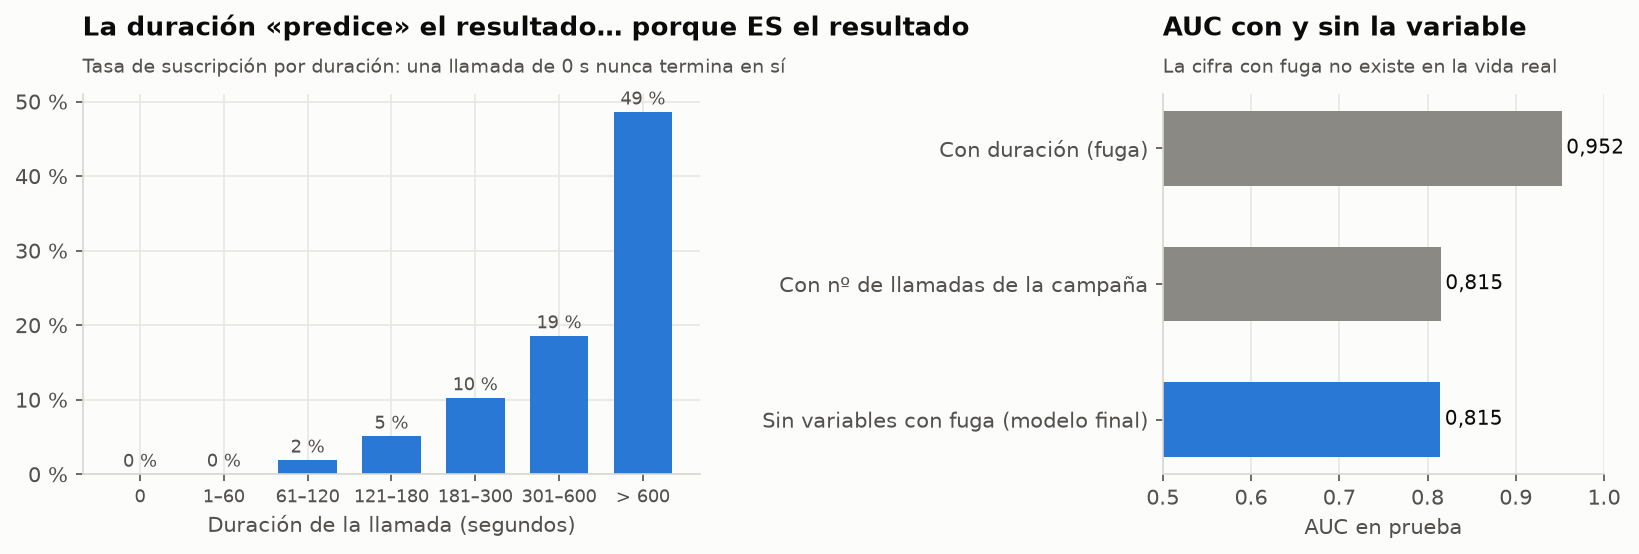

In [7]:
display(Image(RAIZ / "reports" / "figures" / "01_fuga_duracion.png"))

Con `duration` el AUC sube de **0,815 a 0,952**. Ese 0,95 es el que aparece en muchos tutoriales, y **no existe en la vida real**: al momento de decidir la llamada, la duración no se conoce.

**La fuga sutil: `campaign` (nº de contactos en esta campaña, incluido el último).** El banco deja de llamar cuando el cliente acepta, así que el número de llamadas depende del resultado; además, antes de empezar la campaña no se sabe cuántas llamadas hará falta. Aporta poco (AUC +0,001) pero por principio también se excluye.

In [8]:
df.groupby(df["contactos_campana"].clip(upper=8))[config.OBJETIVO].agg(clientes="size", tasa="mean")

,clientes,tasa
contactos_campana,,
1,17634,0.1304
2,10568,0.1146
3,5340,0.1075
4,2650,0.0940
5,1599,0.0750
6,979,0.0766
7,629,0.0604
8,1777,0.0411


## 1.4 ¿Validación temporal o estratificada?

| Opción | A favor | En contra |
|---|---|---|
| **Temporal** (entrenar con el pasado, probar con el futuro) | Es como se usaría el modelo | Aquí el «futuro» (2009-05 → 2010-11) es **otro régimen**: 25 % de éxito vs. 6 %, con variables macro fuera del rango de entrenamiento. Mediría sobre todo el cambio de régimen, con ~10,8 mil filas muy desiguales por mes |
| **Estratificada 80/20** + 5 pliegues | Misma tasa en entrenamiento y prueba, prueba grande (8.236), comparable con la literatura | Optimista si el régimen cambia |

**Decisión:** la evaluación principal es **estratificada** (y todas las decisiones —modelo, calibración, umbral— se toman con **validación cruzada dentro del entrenamiento**; la prueba se mira una sola vez). Y como el riesgo real es el cambio de régimen, se hace una **prueba de estrés temporal** aparte (notebook 3) que muestra cuánto se degrada y cómo mitigarlo.

In [9]:
ent, pru = datos.particion_estratificada(df)
pasado, futuro = datos.particion_temporal(df)
pd.DataFrame({
    "filas": [len(ent), len(pru), len(pasado), len(futuro)],
    "tasa": [ent[config.OBJETIVO].mean(), pru[config.OBJETIVO].mean(),
             pasado[config.OBJETIVO].mean(), futuro[config.OBJETIVO].mean()],
}, index=["estratificada · entrenamiento", "estratificada · prueba",
          "temporal · pasado (hasta 2009-04)", "temporal · futuro (2009-05 →)"])

,filas,tasa
estratificada · entrenamiento,32940,0.1127
estratificada · prueba,8236,0.1127
temporal · pasado (hasta 2009-04),30421,0.0627
temporal · futuro (2009-05 →),10755,0.2540


**Variables finales del modelo** (todas conocidas antes de marcar):

In [10]:
pd.DataFrame({"variable": config.VARIABLES, "descripcion": [config.ETIQUETAS[v] for v in config.VARIABLES],
              "tipo": ["categórica" if v in config.CATEGORICAS else "numérica" for v in config.VARIABLES]})

,variable,descripcion,tipo
0,ocupacion,Ocupación,categórica
1,estado_civil,Estado civil,categórica
2,educacion,Educación,categórica
3,mora,Crédito en mora,categórica
4,hipoteca,Tiene hipoteca,categórica
5,prestamo,Tiene préstamo personal,categórica
6,tipo_contacto,Tipo de teléfono,categórica
7,mes,Mes del contacto,categórica
8,dia_semana,Día de la semana,categórica
9,resultado_previo,Resultado campaña anterior,categórica
